# Week 2 – Machine Learning & AI: Classification and House Price Prediction

This notebook covers both uploaded Week 2 PDFs.

**Practice Set:** Logistic Regression on Titanic, confusion matrix and accuracy, Decision Tree vs KNN, and tuning Decision Tree `max_depth`.

**Week 2 course PDF:** Linear Regression on housing data, Logistic Regression on Titanic, and Mini Project 2 – House Price Prediction with R² evaluation and a predicted-vs-actual plot.

Run cells from top to bottom. You will upload two Kaggle datasets when prompted.

## 1. Install and import libraries

In [1]:
%pip -q install pandas numpy matplotlib seaborn scikit-learn

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, mean_squared_error,
    mean_absolute_error, r2_score
)

os.makedirs("outputs", exist_ok=True)
os.makedirs("visualizations", exist_ok=True)
print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Upload Titanic dataset
Download `train.csv` from the [Kaggle Titanic competition](https://www.kaggle.com/competitions/titanic/data). Upload it below.

In [2]:
print("Upload Titanic train.csv")
uploaded = files.upload()
titanic_file = next(iter(uploaded))
titanic = pd.read_csv(titanic_file)

if "Survived" not in titanic.columns:
    raise ValueError("Expected a Titanic training CSV containing the 'Survived' column.")

display(titanic.head())
print("Dataset shape:", titanic.shape)

Upload Titanic train.csv


Saving Titanic-Dataset.csv to Titanic-Dataset.csv


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Dataset shape: (891, 12)


## 3. Prepare Titanic features and train/test split

In [3]:
# Target: Survived (0 = did not survive, 1 = survived)
drop_cols = [c for c in ["Survived", "PassengerId", "Name", "Ticket", "Cabin"] if c in titanic.columns]
X = titanic.drop(columns=drop_cols)
y = titanic["Survived"]

numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

try:
    ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    ohe = OneHotEncoder(handle_unknown="ignore", sparse=False)

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", ohe)
])
titanic_preprocessor = ColumnTransformer([
    ("num", numeric_pipe, numeric_features),
    ("cat", categorical_pipe, categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Training rows:", len(X_train), "| Testing rows:", len(X_test))

Training rows: 712 | Testing rows: 179


## 4. Train Logistic Regression on Titanic (Practice Question 1)

In [4]:
logistic_model = Pipeline([
    ("preprocessor", titanic_preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])
logistic_model.fit(X_train, y_train)
logistic_pred = logistic_model.predict(X_test)
print("Logistic Regression trained.")

Logistic Regression trained.


## 5. Confusion matrix and accuracy score (Practice Question 2)

Accuracy: 0.8045

Classification report:
              precision    recall  f1-score   support

           0       0.81      0.89      0.85       110
           1       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



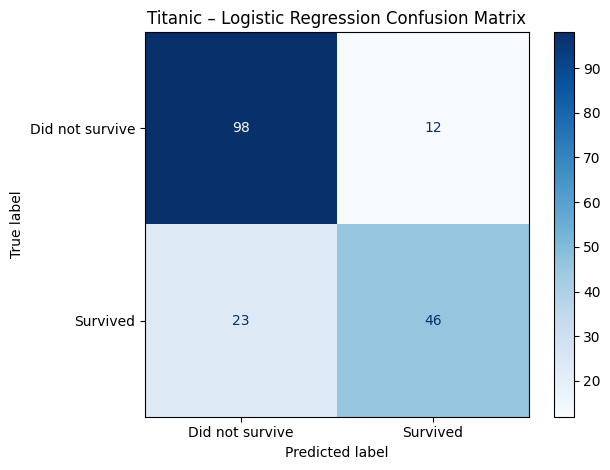

In [5]:
logistic_accuracy = accuracy_score(y_test, logistic_pred)
print(f"Accuracy: {logistic_accuracy:.4f}")
print("\nClassification report:")
print(classification_report(y_test, logistic_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, logistic_pred,
    display_labels=["Did not survive", "Survived"],
    cmap="Blues"
)
plt.title("Titanic – Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.savefig("visualizations/titanic_confusion_matrix.png", dpi=150)
plt.show()

## 6. Compare Decision Tree and KNN accuracy (Practice Question 3)

,Model,Accuracy
1,Decision Tree,0.815642
2,KNN,0.815642
0,Logistic Regression,0.804469


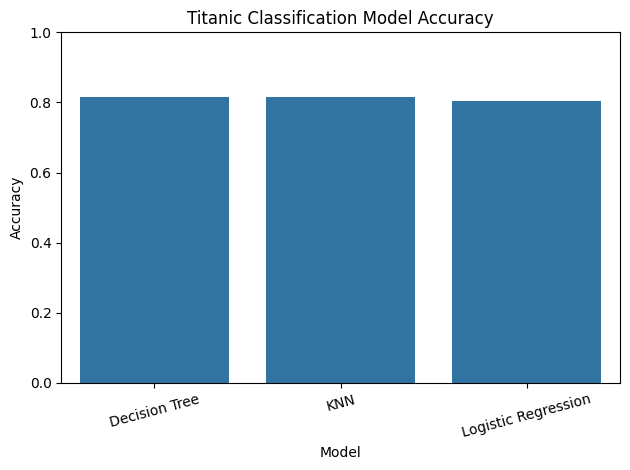

In [6]:
decision_tree = Pipeline([
    ("preprocessor", titanic_preprocessor),
    ("model", DecisionTreeClassifier(random_state=42))
])
knn = Pipeline([
    ("preprocessor", titanic_preprocessor),
    ("model", KNeighborsClassifier(n_neighbors=5))
])

decision_tree.fit(X_train, y_train)
knn.fit(X_train, y_train)

dt_pred = decision_tree.predict(X_test)
knn_pred = knn.predict(X_test)

dt_accuracy = accuracy_score(y_test, dt_pred)
knn_accuracy = accuracy_score(y_test, knn_pred)

comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree", "KNN"],
    "Accuracy": [logistic_accuracy, dt_accuracy, knn_accuracy]
}).sort_values("Accuracy", ascending=False)

display(comparison)
sns.barplot(data=comparison, x="Model", y="Accuracy")
plt.ylim(0, 1)
plt.title("Titanic Classification Model Accuracy")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("visualizations/classification_accuracy_comparison.png", dpi=150)
plt.show()

## 7. Tune Decision Tree `max_depth` (Practice Question 4)

,max_depth,accuracy
0,1,0.776536
1,2,0.759777
2,3,0.793296
3,4,0.793296
4,5,0.765363
5,7,0.815642
6,10,0.804469
7,None,0.815642


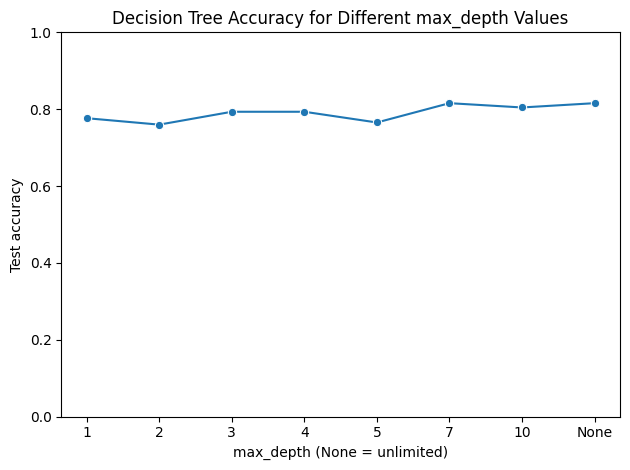

Best tested max_depth: 7
Best test accuracy: 0.8156
A shallow tree can underfit; a very deep tree can overfit. Compare the measured test scores.


In [7]:
depth_values = [1, 2, 3, 4, 5, 7, 10, None]
depth_results = []

for depth in depth_values:
    model = Pipeline([
        ("preprocessor", titanic_preprocessor),
        ("model", DecisionTreeClassifier(max_depth=depth, random_state=42))
    ])
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    depth_results.append({
        "max_depth": "None" if depth is None else str(depth),
        "accuracy": accuracy_score(y_test, pred)
    })

depth_df = pd.DataFrame(depth_results)
display(depth_df)

sns.lineplot(data=depth_df, x="max_depth", y="accuracy", marker="o")
plt.ylim(0, 1)
plt.title("Decision Tree Accuracy for Different max_depth Values")
plt.xlabel("max_depth (None = unlimited)")
plt.ylabel("Test accuracy")
plt.tight_layout()
plt.savefig("visualizations/decision_tree_depth_tuning.png", dpi=150)
plt.show()

best = depth_df.loc[depth_df["accuracy"].idxmax()]
print("Best tested max_depth:", best["max_depth"])
print(f"Best test accuracy: {best['accuracy']:.4f}")
print("A shallow tree can underfit; a very deep tree can overfit. Compare the measured test scores.")

## 8. Upload House Prices dataset

This section completes the Week 2 housing assignment and **Mini Project 2 – House Price Prediction Model**.

Download `train.csv` from [Kaggle – House Prices: Advanced Regression Techniques](https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques/data). Upload it below. It must contain the target column `SalePrice`.

In [9]:
print("Upload House Prices train.csv")
uploaded_house = files.upload()
house_file = next(iter(uploaded_house))
housing = pd.read_csv(house_file)

if "SalePrice" not in housing.columns:
    raise ValueError("Expected the Kaggle House Prices training CSV with a 'SalePrice' column.")

display(housing.head())
print("Dataset shape:", housing.shape)

Upload House Prices train.csv


Saving train.csv to train.csv


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


Dataset shape: (1460, 81)


## 9. Build and train Linear Regression model

In [10]:
y_house = housing["SalePrice"]
X_house = housing.drop(columns=["SalePrice"])

# Id is an identifier rather than a useful house characteristic.
if "Id" in X_house.columns:
    X_house = X_house.drop(columns=["Id"])

house_numeric = X_house.select_dtypes(include=["number"]).columns.tolist()
house_categorical = X_house.select_dtypes(exclude=["number"]).columns.tolist()

try:
    house_ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    house_ohe = OneHotEncoder(handle_unknown="ignore", sparse=False)

house_numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])
house_categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", house_ohe)
])
house_preprocessor = ColumnTransformer([
    ("num", house_numeric_pipe, house_numeric),
    ("cat", house_categorical_pipe, house_categorical)
])

Xh_train, Xh_test, yh_train, yh_test = train_test_split(
    X_house, y_house, test_size=0.2, random_state=42
)

house_model = Pipeline([
    ("preprocessor", house_preprocessor),
    ("model", LinearRegression())
])
house_model.fit(Xh_train, yh_train)
house_pred = house_model.predict(Xh_test)
print("Housing Linear Regression model trained successfully.")

Housing Linear Regression model trained successfully.


## 10. Evaluate the model using R² score

In [11]:
mae = mean_absolute_error(yh_test, house_pred)
mse = mean_squared_error(yh_test, house_pred)
rmse = np.sqrt(mse)
r2 = r2_score(yh_test, house_pred)

print(f"MAE:  {mae:,.2f}")
print(f"MSE:  {mse:,.2f}")
print(f"RMSE: {rmse:,.2f}")
print(f"R² score: {r2:.4f}")

MAE:  18,287.85
MSE:  868,806,561.31
RMSE: 29,475.52
R² score: 0.8867


## 11. Plot predicted vs actual house prices (Mini Project 2)

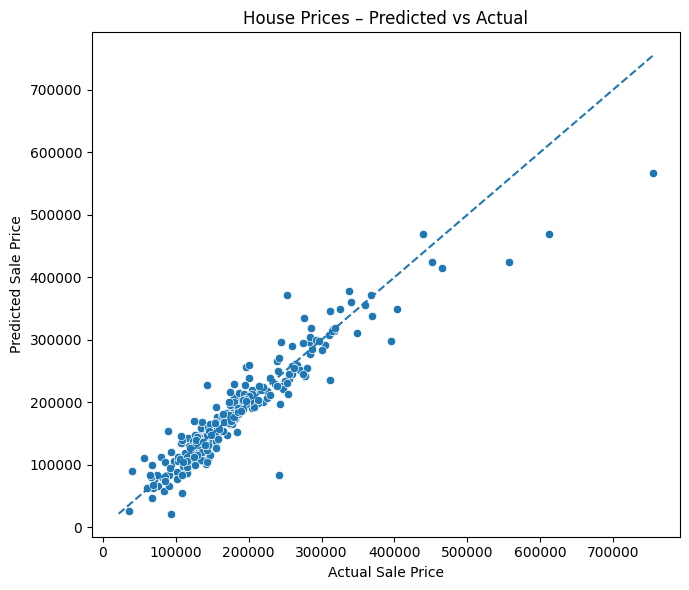

In [12]:
plt.figure(figsize=(7, 6))
sns.scatterplot(x=yh_test, y=house_pred)
low = min(yh_test.min(), house_pred.min())
high = max(yh_test.max(), house_pred.max())
plt.plot([low, high], [low, high], linestyle="--")
plt.title("House Prices – Predicted vs Actual")
plt.xlabel("Actual Sale Price")
plt.ylabel("Predicted Sale Price")
plt.tight_layout()
plt.savefig("visualizations/house_predicted_vs_actual.png", dpi=150)
plt.show()

## 12. Example prediction

In [13]:
# Demonstrate prediction for one held-out house.
example_house = Xh_test.iloc[[0]]
example_prediction = house_model.predict(example_house)[0]
example_actual = yh_test.iloc[0]

print(f"Predicted price: ${example_prediction:,.2f}")
print(f"Actual price:    ${example_actual:,.2f}")

Predicted price: $157,608.87
Actual price:    $154,500.00


## 13. Save output files

In [14]:
comparison.to_csv("outputs/titanic_model_accuracy_comparison.csv", index=False)
depth_df.to_csv("outputs/decision_tree_depth_comparison.csv", index=False)

print("Saved output CSV files:")
print("- outputs/titanic_model_accuracy_comparison.csv")
print("- outputs/decision_tree_depth_comparison.csv")
print("\nVisualisations are saved in the visualizations/ folder.")

Saved output CSV files:
- outputs/titanic_model_accuracy_comparison.csv
- outputs/decision_tree_depth_comparison.csv

Visualisations are saved in the visualizations/ folder.


## 14. Assignment checklist

| Requirement | Section |
|---|---:|
| Logistic Regression on Titanic | 4 |
| Confusion matrix and accuracy | 5 |
| Decision Tree vs KNN comparison | 6 |
| Tune Decision Tree `max_depth` | 7 |
| Linear Regression on housing data | 8–9 |
| Predict house prices | 9 and 12 |
| Evaluate R² score | 10 |
| Plot predicted vs actual values | 11 |

**Datasets required:** Upload the Titanic competition `train.csv` in Section 2 and the House Prices competition `train.csv` in Section 8. The two files have the same filename on Kaggle but are different datasets. Results depend on the dataset and train/test split; no particular accuracy is guaranteed.